<a href="https://colab.research.google.com/github/BrunaAguiar20/Projeto-Aprendizado-de-Maquina-I/blob/main/A7_Aprendizado_de_Maquina_ex_projeto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<img src="http://meusite.mackenzie.br/rogerio/mackenzie_logo/UPM.2_horizontal_vermelho.jpg"  width=300, align="right">
<br>
<br>
<br>
<br>
<br>

# **Classificação dos Preços de Combustíveis no Brasil**
---

$\rightarrow$ **esta célula deve ser removida na entrega do projeto**

# Objetivo

Neste trabalho você deve obrigatoriamente trabalhar em grupo de 2-4 alunos e desenvolver uma solução de aprendizado supervisionado para algum problema de interesse do grupo. Os problemas poderão ser de classificação ou de regressão.

## Descrição do Projeto

O trabalho deve ser original e desenvolvido em R ou Python notebook com um conjunto de dados próprios e originais definidos. Entendam como dados próprios e originais dados que são originais de empresas ou entidades, podendo ser bases públicas. Dados de ONGs, empresas privadas ou governo, são exemplos de bases válidas. Bases de repositórios públicos como Kaggle e UCI, que fornecem bases prontas não são originais. Tenha em mente: você deve construir uma base de dados nova para o seu problema, é essa a ideia de dados originais. Se tiver dúvidas consulte o professor antes de empregar uma base.

Os dados devem suportar um problema relevante e adequado para o aprendizado supervisionado. Assim, não podem ser empregadas bases artificiais e problemas muito simples. Devem ser evitadas também Séries Temporais como séries financeiras (como ações) e de dados climáticos que requerem outras técnicas não detalhadas aqui.

As bases devem conter um mínimo de 1000 instâncias. Consulte o professor para uso de um número menor de instâncias para dados próprios de uma empresa por exemplo.

Você deve implementar ao menos dois modelos, comparar e discutir os seus resultados. Seu notebook deve ser 100% executável e incluir todo necessário para construção dos dados, entendimento do problema e da solução.

Deve ainda ser entregue uma apresentação em **vídeo (até 5min)** dos resultados.



$\rightarrow$ **esta célula deve ser removida na entrega do projeto**

Siga este template para entrega do seu projeto. O código deste notebook precisa ser 100% executável, sem a necessidade de qualquer operação adicional como por exemplo a download, cópia ou alteração de arquivos. Crie assim repositórios públicos para suas bases de dados, por exemplo, disponibilizando-as no GitHub.

## Entregas na Tarefa do Moodle

1. Poste este Python notebook (.ipynb) modificado com o seu projeto.
2. Poste o endereço (link) do Python notebook do seu projeto compartilhado (público para leitura) nos comentários da tarefa
3. Um vídeo de até 5min com a apresentação do seu projeto em formato .mp4
4. Opcional, poste o .pptx da apresentação

## Vídeo

O vídeo deve contemplar:

1. Apresentação e Justificativa do seu problema
2. A abordagem dada ao problema (fonte dos dados, transformações, modelos avaliados)
3. A solução e seus resultados
4. Diferenciais e Melhorias Futuras do trabalho (modelos e técnicas diferenciadas que foram empregadas, limitações do modelo atual e como melhora-las etc.)







In [1]:
#@title Identificação do Grupo

#@markdown Integrantes do Grupo (*informe \<TIA\>,\<nome\>*)
Aluno1 = '10752215, Bruna da Silva Aguiar' #@param {type:"string"}
Aluno2 = 'None' #@param {type:"string"}
Aluno3 = 'None' #@param {type:"string"}
Aluno4 = 'None' #@param {type:"string"}

# **Apresentação**

Neste projeto, utilizamos dados reais sobre preços de combustíveis coletados em postos de diferentes regiões do Brasil. Aplicamos dois algoritmos de aprendizado de máquina supervisionado para tentar identificar se um preço está acima ou abaixo da mediana do respectivo combustível.

Escolhemos esse tema porque o preço dos combustíveis é relevante para consumidores, empresas e atividades de transporte. Além disso, a base de dados é pública e permite estudar um problema de classificação com informações reais.

# Problema

Pergunta do projeto: considerando o tipo de combustível, o estado, o município, a bandeira do posto e o mês da coleta, é possível prever se o preço será classificado como alto ou baixo?

A regra utilizada será:
- 0 — Baixo: preço menor ou igual à mediana do mesmo produto.
- 1 — Alto: preço maior que a mediana do mesmo produto.
Exemplo ilustrativo: se a mediana da gasolina fosse R$ 6,00, um preço de R$ 5,90 seria baixo e um preço de R$ 6,20 seria alto.

Usaremos o Valor de Venda somente para criar a resposta correta dos registros. Ele não será uma variável de entrada para os modelos.
Neste estudo, alto e baixo significam apenas a posição do preço em relação à mediana na amostra do primeiro semestre de 2026. Não significa que o preço seja justo, abusivo ou caro em termos absolutos.



# Referencial Teórico

- Aprendizado supervisionado: o algoritmo aprende a partir de exemplos com características de entrada e uma resposta conhecida.
- Classificação binária: previsão entre duas categorias. Neste trabalho, baixo (0) e alto (1).
- Mediana: valor central de um conjunto de preços ordenados. É menos influenciada por valores extremos do que a média.
- Árvore de Decisão: organiza decisões em regras sucessivas para separar os registros em classes.
- Random Forest: combina várias árvores de decisão para produzir uma classificação.
- Acurácia: proporção total de previsões corretas. Precisão, recall e F1-score: ajudam a avaliar o desempenho nas duas classes.
- Matriz de confusão: tabela que mostra quantos preços altos e baixos foram classificados corretamente ou incorretamente.
A metodologia segue os conceitos apresentados na documentação do scikit-learn sobre árvores, florestas aleatórias e métricas de classificação, disponíveis nas referências.

# Metodologia

1. Carregar o CSV original da ANP, referente ao primeiro semestre de 2026.
2. Selecionar as colunas necessárias, converter os preços em números e extrair o mês da coleta.
3. Selecionar, de maneira aleatória e reproduzível, 20.000 registros reais para facilitar o treinamento.
4. Dividir os dados em treinamento e teste, sem repetir um mesmo CNPJ de posto nos dois conjuntos.
5. Calcular a mediana do preço por produto usando somente os dados de treinamento e criar as classes 0 e 1.
6. Treinar dois modelos: Árvore de Decisão e Random Forest.
7. Comparar os resultados utilizando o mesmo conjunto de teste.
Variáveis de entrada (X): Produto, Estado, Município, Bandeira e Mês.
Variável-alvo (y): Classificação do preço (0 ou 1).

Separar os dados antes de calcular a mediana evita usar os preços do conjunto de teste para definir o limite de classificação.



# Resultados

Na execução realizada com o CSV fornecido, foram selecionados 20.000 registros, dos quais 16.068 foram usados para treinamento e 3.932 para teste.

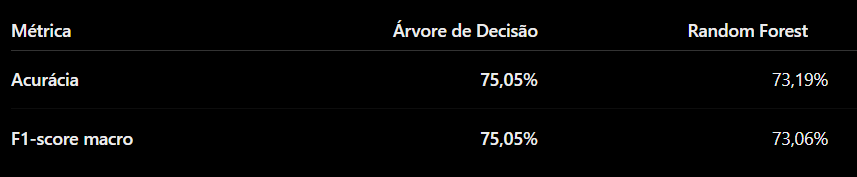


A Árvore de Decisão obteve o melhor desempenho neste teste. A implementação a seguir apresenta os códigos utilizados, os preços medianos encontrados, os gráficos e as matrizes de confusão.

# **Implementação**

# Base de Dados

Utilizamos o arquivo combustiveis_anp_2026.csv, que corresponde à base enviada “Preços semestrais - AUTOMOTIVOS_2026.01”, disponibilizada pela Agência Nacional do Petróleo, Gás Natural e Biocombustíveis (ANP).

A base original contém 422.418 registros e 16 colunas, incluindo informações sobre os postos, os combustíveis e os preços de venda. Escolhemos apenas as informações necessárias ao problema, sem inventar valores ou registros.

Para executar, mantenha o CSV e este notebook na mesma pasta. No VS Code/Jupyter, execute as células de cima para baixo.



In [4]:
# Importação das bibliotecas

import pandas as pd
import matplotlib.pyplot as plt
import gdown

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

In [5]:
# Importação da base de dados

# Identificador do arquivo no Google Drive
id_arquivo = "1b5wAt8TuXi2-dAUr95Dz-L6eh1mUGuwM"

# Baixar a base diretamente do Google Drive
gdown.download(
    id=id_arquivo,
    output="combustiveis_anp_2026.csv",
    quiet=False
)

# Carregar a base de dados
df = pd.read_csv(
    "combustiveis_anp_2026.csv",
    sep=";",
    encoding="utf-8-sig",
    low_memory=False
)

# Visualizar as dimensões da base
print("Dimensões da base:", df.shape)

# Visualizar os primeiros registros
display(df.head())


Downloading...
From: https://drive.google.com/uc?id=1b5wAt8TuXi2-dAUr95Dz-L6eh1mUGuwM
To: /content/combustiveis_anp_2026.csv
100%|██████████| 72.1M/72.1M [00:00<00:00, 168MB/s]


Dimensões da base: (422418, 16)


,Regiao - Sigla,Estado - Sigla,Municipio,Revenda,CNPJ da Revenda,Nome da Rua,Numero Rua,Complemento,Bairro,Cep,Produto,Data da Coleta,Valor de Venda,Valor de Compra,Unidade de Medida,Bandeira
0,N,AC,CRUZEIRO DO SUL,AMAZONIA COMERCIO DE DERIVADOS DE PETROLEO LTDA,01.492.748/0003-83,AVENIDA COPACABANA,440,NaN,COPACABANA,69980-000,GASOLINA,02/01/2026,"7,97",NaN,R$ / litro,IPIRANGA
1,N,AC,CRUZEIRO DO SUL,AMAZONIA COMERCIO DE DERIVADOS DE PETROLEO LTDA,01.492.748/0003-83,AVENIDA COPACABANA,440,NaN,COPACABANA,69980-000,DIESEL,02/01/2026,"8,15",NaN,R$ / litro,IPIRANGA
2,N,AC,CRUZEIRO DO SUL,AMAZONIA COMERCIO DE DERIVADOS DE PETROLEO LTDA,01.492.748/0003-83,AVENIDA COPACABANA,440,NaN,COPACABANA,69980-000,DIESEL S10,02/01/2026,"8,17",NaN,R$ / litro,IPIRANGA
3,N,AC,RIO BRANCO,AUTO POSTO AMAPA LTDA,00.529.581/0001-53,VIA CHICO MENDES,3570,NaN,AREAL,69906-119,GASOLINA,02/01/2026,"7,29",NaN,R$ / litro,VIBRA
4,N,AC,RIO BRANCO,AUTO POSTO AMAPA LTDA,00.529.581/0001-53,VIA CHICO MENDES,3570,NaN,AREAL,69906-119,GASOLINA ADITIVADA,02/01/2026,"7,39",NaN,R$ / litro,VIBRA


In [6]:
# Quantidade de registros por combustível
print(df['Produto'].value_counts())

# Verificar se existem informações faltando nas colunas escolhidas
print('\nDados ausentes por coluna:')
print(df.isna().sum())

Produto
GASOLINA              110925
ETANOL                 93893
GASOLINA ADITIVADA     86231
DIESEL S10             77118
DIESEL                 45814
GNV                     8437
Name: count, dtype: int64

Dados ausentes por coluna:
Regiao - Sigla            0
Estado - Sigla            0
Municipio                 0
Revenda                   0
CNPJ da Revenda           0
Nome da Rua               0
Numero Rua                6
Complemento          326259
Bairro                  728
Cep                       0
Produto                   0
Data da Coleta            0
Valor de Venda            0
Valor de Compra      422418
Unidade de Medida         0
Bandeira                  0
dtype: int64


In [10]:
# Converter preço e data para os formatos corretos
df['Valor de Venda'] = pd.to_numeric(
    df['Valor de Venda'].astype(str).str.replace(',', '.', regex=False),
    errors='coerce'
)

df['Data da Coleta'] = pd.to_datetime(
    df['Data da Coleta'], format='%d/%m/%Y', errors='coerce'
)

# Colunas necessárias para o projeto
colunas = [
    'Produto',
    'Estado - Sigla',
    'Municipio',
    'Bandeira',
    'Data da Coleta',
    'Valor de Venda',
    'CNPJ da Revenda'
]

# Excluir registros inválidos ou repetidos
df = df.dropna(subset=colunas)
df = df[df['Valor de Venda'] > 0].drop_duplicates()

# Selecionar 20 mil registros e identificar o mês
df = df.sample(n=20000, random_state=42).reset_index(drop=True)
df['Mes'] = df['Data da Coleta'].dt.month.astype(str)

print('Registros selecionados:', len(df))
print('Período:', df['Data da Coleta'].min().date(), 'até', df['Data da Coleta'].max().date())
display(df[['Produto', 'Estado - Sigla', 'Municipio', 'Valor de Venda', 'Mes']].head())

Registros selecionados: 20000
Período: 2026-01-01 até 2026-06-30


,Produto,Estado - Sigla,Municipio,Valor de Venda,Mes
0,GASOLINA,SP,SANTO ANDRE,5.99,3
1,DIESEL S10,SP,SOROCABA,6.09,1
2,GASOLINA,RS,SANTANA DO LIVRAMENTO,6.99,4
3,GASOLINA ADITIVADA,SP,OSASCO,7.47,4
4,DIESEL S10,MT,VARZEA GRANDE,6.49,2


# **Separação em treinamento e teste**

Dividimos os registros em dois conjuntos: o treinamento ensina os modelos e o teste verifica a capacidade de classificar novos registros.

A separação utiliza o CNPJ da Revenda para evitar que o mesmo posto apareça nos dois conjuntos. Esse cuidado torna a avaliação mais representativa para estabelecimentos não vistos durante o treinamento.

In [11]:
# Dividir por posto: aproximadamente 80% para treino e 20% para teste
divisao = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
indice_treino, indice_teste = next(divisao.split(df, groups=df['CNPJ da Revenda']))

treino = df.iloc[indice_treino].copy()
teste = df.iloc[indice_teste].copy()

print('Registros de treinamento:', len(treino))
print('Registros de teste:', len(teste))

Registros de treinamento: 16068
Registros de teste: 3932


In [14]:
# Cálculo da mediana e criação das classes

# Calcular a mediana do preço de cada combustível no treinamento
medianas = treino.groupby('Produto')['Valor de Venda'].median()

print('Mediana por combustível (R$):')
display(medianas.to_frame('Mediana (R$)'))

# Criar a classificação 0 (baixo) ou 1 (alto)
for tabela in [treino, teste]:
    tabela['Classe'] = (
        tabela['Valor de Venda'] > tabela['Produto'].map(medianas)
    ).astype(int)

# Exemplos de como os preços foram classificados
display(treino[['Produto', 'Valor de Venda', 'Classe']].head(10))

Mediana por combustível (R$):


,Mediana (R$)
Produto,
DIESEL,6.75
DIESEL S10,6.99
ETANOL,4.69
GASOLINA,6.54
GASOLINA ADITIVADA,6.74
GNV,4.49


,Produto,Valor de Venda,Classe
0,GASOLINA,5.99,0
1,DIESEL S10,6.09,0
2,GASOLINA,6.99,1
3,GASOLINA ADITIVADA,7.47,1
6,ETANOL,4.69,0
7,DIESEL S10,5.89,0
8,GASOLINA ADITIVADA,6.29,0
10,GASOLINA ADITIVADA,6.39,0
11,ETANOL,4.59,0
12,DIESEL,6.40,0


In [15]:
# Quantidade de preços baixos e altos no treinamento
quantidade = treino['Classe'].map({0: 'Baixo', 1: 'Alto'}).value_counts()

print(quantidade)

Classe
Baixo    8382
Alto     7686
Name: count, dtype: int64


## **Modelo 1**

*Descreva resumidamente o modelo empregado.*


### **Modelo 1:** Preparação dos Dados


In [16]:
# Selecionar as mesmas variáveis para os dois modelos
variaveis = ['Produto', 'Estado - Sigla', 'Municipio', 'Bandeira', 'Mes']

X_treino = treino[variaveis]
X_teste = teste[variaveis]
y_treino = treino['Classe']
y_teste = teste['Classe']

print('Variáveis usadas:', variaveis)
print('Treinamento:', X_treino.shape, '| Teste:', X_teste.shape)

Variáveis usadas: ['Produto', 'Estado - Sigla', 'Municipio', 'Bandeira', 'Mes']
Treinamento: (16068, 5) | Teste: (3932, 5)


### **Modelo 1:** Modelo


In [17]:
# Treinar o Modelo 1: Árvore de Decisão
modelo_arvore = make_pipeline(
    OneHotEncoder(handle_unknown='ignore'),
    DecisionTreeClassifier(max_depth=12, min_samples_leaf=10, random_state=42)
)

modelo_arvore.fit(X_treino, y_treino)
previsao_arvore = modelo_arvore.predict(X_teste)

print('Árvore de Decisão treinada com sucesso!')

Árvore de Decisão treinada com sucesso!


### **Modelo 1:** Resultados


Acurácia da Árvore de Decisão: 75.05%
              precision    recall  f1-score   support

       Baixo       0.78      0.73      0.75      2058
        Alto       0.72      0.78      0.75      1874

    accuracy                           0.75      3932
   macro avg       0.75      0.75      0.75      3932
weighted avg       0.75      0.75      0.75      3932



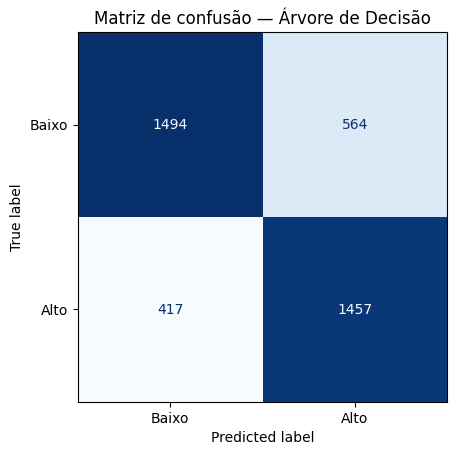

In [18]:
# Avaliação do Modelo 1
acuracia_arvore = accuracy_score(y_teste, previsao_arvore)
f1_arvore = f1_score(y_teste, previsao_arvore, average='macro')

print(f'Acurácia da Árvore de Decisão: {acuracia_arvore:.2%}')
print(classification_report(y_teste, previsao_arvore, target_names=['Baixo', 'Alto']))

ConfusionMatrixDisplay.from_predictions(
    y_teste, previsao_arvore, display_labels=['Baixo', 'Alto'], cmap='Blues', colorbar=False
)
plt.title('Matriz de confusão — Árvore de Decisão')
plt.show()

## **Modelo 2**

*Descreva resumidamente o modelo empregado.*


### **Modelo 2:** Preparação dos Dados


In [19]:
# Conferir os dados compartilhados pelos dois modelos
print('Registros para treinar os dois modelos:', len(X_treino))
print('Registros para testar os dois modelos:', len(X_teste))
print('Classes usadas:', sorted(y_treino.unique()))

Registros para treinar os dois modelos: 16068
Registros para testar os dois modelos: 3932
Classes usadas: [np.int64(0), np.int64(1)]


### **Modelo 2:** Modelo


In [20]:
# Treinar o Modelo 2: Random Forest
modelo_floresta = make_pipeline(
    OneHotEncoder(handle_unknown='ignore'),
    RandomForestClassifier(n_estimators=80, max_depth=15,
                           min_samples_leaf=5, random_state=42, n_jobs=-1)
)

modelo_floresta.fit(X_treino, y_treino)
previsao_floresta = modelo_floresta.predict(X_teste)

print('Random Forest treinada com sucesso!')

Random Forest treinada com sucesso!


### **Modelo 2:** Resultados


Acurácia da Random Forest: 73.19%
              precision    recall  f1-score   support

       Baixo       0.73      0.77      0.75      2058
        Alto       0.73      0.69      0.71      1874

    accuracy                           0.73      3932
   macro avg       0.73      0.73      0.73      3932
weighted avg       0.73      0.73      0.73      3932



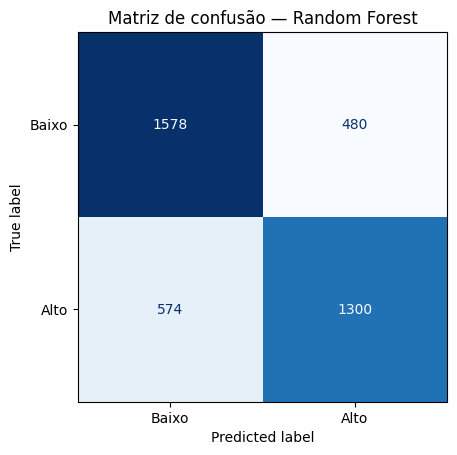

In [21]:
# Avaliação do Modelo 2
acuracia_floresta = accuracy_score(y_teste, previsao_floresta)
f1_floresta = f1_score(y_teste, previsao_floresta, average='macro')

print(f'Acurácia da Random Forest: {acuracia_floresta:.2%}')
print(classification_report(y_teste, previsao_floresta, target_names=['Baixo', 'Alto']))

ConfusionMatrixDisplay.from_predictions(
    y_teste, previsao_floresta, display_labels=['Baixo', 'Alto'], cmap='Blues', colorbar=False
)
plt.title('Matriz de confusão — Random Forest')
plt.show()

# **Comparação dos dois modelos**

# **Conclusão**

O projeto mostrou que é possível utilizar dados reais sobre combustíveis para construir um problema de classificação supervisionada. Criamos duas categorias — preço alto e preço baixo — considerando a mediana do próprio produto no primeiro semestre de 2026.

Na avaliação com 3.932 registros de teste, a Árvore de Decisão apresentou acurácia de 75,05% e F1-score macro de 75,05%. A Random Forest obteve acurácia de 73,19% e F1-score macro de 73,06%. Portanto, a Árvore de Decisão apresentou o melhor resultado neste experimento, mesmo sendo um algoritmo mais simples.

Isso indica que informações como tipo de combustível, localização, bandeira e mês da coleta ajudam a explicar parte das diferenças de preços, mas não são suficientes para uma classificação perfeita. O preço também depende de fatores que não estão entre as variáveis utilizadas, como custos e condições específicas do estabelecimento.

Limitações: o modelo utiliza uma amostra de 20 mil registros de um único semestre e uma classificação relativa à mediana. O desempenho poderá mudar em outros períodos e localidades. A mediana adotada é a do treinamento e não é um limite oficial de preço.

Melhorias futuras: avaliar outros semestres, testar novos parâmetros e considerar características adicionais dos postos e dos mercados locais, quando estiverem disponíveis.

Originalidade: a fonte é governamental e construímos a amostra e a variável-alvo para este problema. O grupo deve confirmar com o professor se isso atende integralmente ao requisito de construção de uma base nova.



# **Referências**

- AGÊNCIA NACIONAL DO PETRÓLEO, GÁS NATURAL E BIOCOMBUSTÍVEIS (ANP). Série Histórica de Preços de Combustíveis e de GLP. Arquivo: Preços semestrais — Automotivos, 1º semestre de 2026. Disponível em: https://www.gov.br/anp/pt-br/centrais-de-conteudo/dados-abertos/serie-historica-de-precos-de-combustiveis. Acesso em: 8 nov. 2026.


---

In [29]:
#@title Avaliação
Completo = 10 #@param {type:"slider", min:0, max:10, step:1}
#@markdown Projeto cumpre todos os itens pedidos.
Relevancia = 9 #@param {type:"slider", min:0, max:10, step:1}
#@markdown As seleções de dados e eventos para análise são relevantes e justificados.
Tecnicas = 6 #@param {type:"slider", min:0, max:10, step:1}
#@markdown As técnicas de empregadas são adequadas e corretamente aplicadas.
Apresentacao = 7 #@param {type:"slider", min:0, max:10, step:1}
#@markdown A apresentação dos resultados é clara e objetiva.
Analise = 8 #@param {type:"slider", min:0, max:10, step:1}
#@markdown As premissas de análise se justificam e a analise é correta.
Conclusao = 7 #@param {type:"slider", min:0, max:10, step:1}
#@markdown As conclusões são justificadas e relevantes
Bonus = 0.5 #@param {type:"slider", min:0, max:1, step:0.5}
#@markdown A critério do professor por inovações na abordagem e no uso de técnicas de Análise de Dados








In [30]:
#@markdown ### Nota Final
nota = Completo + Relevancia + Tecnicas + Apresentacao + Analise + Conclusao

nota = nota / 6 + Bonus

print(f'Nota final do trabalho {nota :.1f}')

import numpy as np
import pandas as pd

alunos = pd.DataFrame()

lista_tia = []
lista_nome = []

for i in range(1,6):
  exec("if Aluno" + str(i) + " !='None':  lista = Aluno" + str(i) + ".split(','); lista_tia.append(lista[0]); lista_nome.append(lista[1].upper())")

alunos['tia'] = lista_tia
alunos['nome'] = lista_nome
alunos['nota'] = np.round(nota,1)
print()
alunos

Nota final do trabalho 8.3



,tia,nome,nota
0,10752215,BRUNA DA SILVA AGUIAR,8.3
1,1115677,DANIEL HENRIQUE,8.3
